Task 8: Graph-Based MST Clustering (Breast Cancer Wisconsin Dataset)
● Exam Task:
1. Load the Breast Cancer dataset (or a sampled 100–150 record subset for rapid
graph calculation), select numerical attributes, and standardize them
2. Construct a pairwise Euclidean distance matrix and compute the Minimum
Spanning Tree (MST) using
scipy.sparse.csgraph.minimum_spanning_tree (or networkx)
3. Partition the graph into clusters by removing the single largest edge𝐾 = 2
weight in the MST
4. Assign cluster labels to the two resulting connected components and evaluate
clustering performance against ground truth labels using the Adjusted Rand
Index (ARI) or Silhouette Score

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.spatial.distance import pdist, squareform

# 1. Load the Breast Cancer dataset and subset 150 records for rapid calculation
data = load_breast_cancer()
X = data.data[:150]
y = data.target[:150]

# Standardize numerical attributes
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Data subset shape: {X_scaled.shape}")

Data subset shape: (150, 30)


In [2]:
# 2. Construct pairwise Euclidean distance matrix and compute the Minimum Spanning Tree (MST)
dist_matrix = squareform(pdist(X_scaled, metric='euclidean'))

# Create a NetworkX complete graph
G = nx.Graph()
num_nodes = len(X_scaled)
for i in range(num_nodes):
    for j in range(i + 1, num_nodes):
        G.add_edge(i, j, weight=dist_matrix[i, j])

# Compute the MST
mst = nx.minimum_spanning_tree(G)
print(f"MST constructed with {mst.number_of_nodes()} nodes and {mst.number_of_edges()} edges.")

MST constructed with 150 nodes and 149 edges.


In [3]:
# 3. Partition the graph into 2 clusters by removing the single largest edge weight in the MST
edges = sorted(mst.edges(data=True), key=lambda x: x[2]['weight'], reverse=True)
largest_edge = edges[0]

mst_partitioned = mst.copy()
mst_partitioned.remove_edge(largest_edge[0], largest_edge[1])

print(f"Removed largest edge between node {largest_edge[0]} and node {largest_edge[1]} with weight: {largest_edge[2]['weight']:.4f}")

Removed largest edge between node 68 and node 112 with weight: 8.5974


In [4]:
# 4. Assign cluster labels to the two resulting connected components and evaluate performance
components = list(nx.connected_components(mst_partitioned))

predicted_labels = np.zeros(num_nodes, dtype=int)
for cluster_id, component in enumerate(components):
    for node in component:
        predicted_labels[node] = cluster_id

# Evaluation using Adjusted Rand Index (ARI) and Silhouette Score
ari = adjusted_rand_score(y, predicted_labels)
sil_score = silhouette_score(X_scaled, predicted_labels)

print(f"--- Clustering Performance ---")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Silhouette Score: {sil_score:.4f}")

--- Clustering Performance ---
Adjusted Rand Index (ARI): 0.0032
Silhouette Score: 0.4614


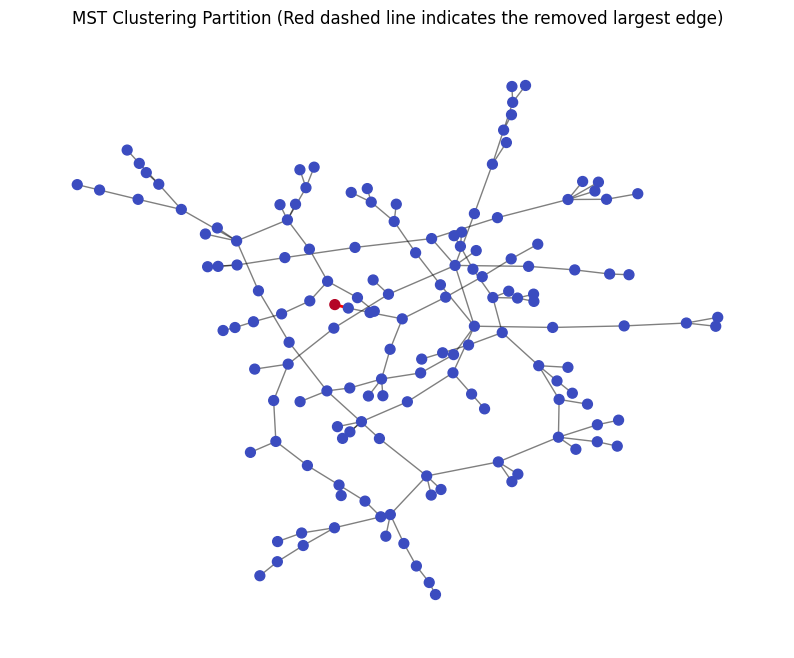

In [5]:
# Optional: Visualize the partitioned MST structure
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(mst, seed=42)

# Draw nodes colored by predicted cluster
nx.draw_networkx_nodes(mst, pos, node_size=50, node_color=predicted_labels, cmap=plt.cm.coolwarm)
# Draw remaining MST edges
nx.draw_networkx_edges(mst_partitioned, pos, alpha=0.5)
# Highlight the removed edge
nx.draw_networkx_edges(mst, pos, edgelist=[(largest_edge[0], largest_edge[1])], style='dashed', edge_color='red', width=2)

plt.title("MST Clustering Partition (Red dashed line indicates the removed largest edge)")
plt.axis('off')
plt.show()